# Results of the final model

The final model of the [roadmap](../ROADMAP.md) on the test split, Q1 2025: the mean of the forecasts of the LSTM of `configs/lstm.toml` with three seeds and of Ridge, 50/50, retrained on training and validation data.

The test split was evaluated once in step 7 (`reports/test_results.md`); this notebook only looks at that result in more detail. It needs the dataset in `data/raw/` and the final models in `models/final/`.

The inputs of the forecast day (weather, wind, solar, residual load) are measured values used as perfect forecasts, so with real forecasts the errors would be larger. All errors are in EUR/MWh; a positive error means the forecast was too high.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from spotforecast.models.baselines import naive_forecasts, stack_windows
from spotforecast.predict import (COLORS, CONTEXT_COLOR, LABELS, MUTED_COLOR, TEXT_COLOR, FinalModel, plot_day,
                                  style_axes, to_eur)

plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110})

model = FinalModel(torch.device("cuda" if torch.cuda.is_available() else "cpu"))
ds = model.splits["test"]
X, Y = stack_windows(ds)
days = ds.forecast_starts()
# the 24 hours of every forecast day as local wall-clock times, for the time axes
hours = ds.dates[(ds.usable_idxs[:, None] + ds.window + np.arange(ds.horizon)).ravel()].tz_localize(None)
actual = to_eur(Y[:, :, 0], ds)

naive = naive_forecasts(X, ds.horizon)
scaled = {"persistence": naive["persistence"], "day D-1": naive["day D-1"], **model.forecast(X, Y)}
scaled.update({f"lstm seed {i}": forecast(X, Y) for i, forecast in enumerate(model.lstms, 1)})
forecasts = {name: to_eur(pred, ds) for name, pred in scaled.items()}
errors = {name: pred - actual for name, pred in forecasts.items()}
daily_mae = {name: np.abs(err).mean(axis=1) for name, err in errors.items()}

# the three parts of the final model in the colors of the README figures, the baseline day D-1 as gray context
MAIN = ["ridge", "lstm mean", "final model"]
label = lambda name: LABELS.get(name, name.replace("lstm", "LSTM"))
color = lambda name: COLORS.get(name, CONTEXT_COLOR)


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))


print(f"test split: {days[0]:%d %b %Y} to {days[-1]:%d %b %Y}, {len(days)} days, {actual.size} hours; "
      f"price {actual.min():.0f} to {actual.max():.0f}, mean {actual.mean():.1f} EUR/MWh")

test split: 01 Jan 2025 to 31 Mar 2025, 89 days, 2136 hours; price -15 to 583, mean 113.0 EUR/MWh


## 1. Overview

All forecasts on the test split. **Bias** is the mean of the signed errors (negative: too low on average), **within 10 / 20** the share of hours with an error below 10 and 20 EUR/MWh. The MAE values are those of `reports/test_results.md`.

In [2]:
order = ["persistence", "day D-1", "ridge", "lstm seed 1", "lstm seed 2", "lstm seed 3", "lstm mean", "final model"]
summary = pd.DataFrame({label(name): {
    "MAE": np.abs(errors[name]).mean(),
    "RMSE": np.sqrt((errors[name] ** 2).mean()),
    "bias": errors[name].mean(),
    "median abs. error": np.median(np.abs(errors[name])),
    "max abs. error": np.abs(errors[name]).max(),
    "within 10": (np.abs(errors[name]) < 10).mean(),
    "within 20": (np.abs(errors[name]) < 20).mean(),
} for name in order}).T
display(summary.style.format("{:.1f}").format("{:.0%}", subset=["within 10", "within 20"]))

,MAE,RMSE,bias,median abs. error,max abs. error,within 10,within 20
persistence,29.8,45.5,-11.8,18.2,460.5,32%,53%
day D-1,29.0,45.3,-1.3,17.7,433.7,33%,54%
Ridge,15.6,24.8,-4.2,11.7,393.1,43%,74%
LSTM seed 1,17.2,25.6,6.5,11.9,357.1,44%,69%
LSTM seed 2,15.6,24.5,5.5,10.5,374.2,48%,73%
LSTM seed 3,14.9,23.5,4.1,10.1,366.7,50%,75%
"LSTM, mean of 3 seeds",15.5,24.1,5.4,10.7,366.0,48%,73%
final model (LSTM + Ridge),13.9,22.9,0.6,9.5,379.6,52%,78%


## 2. The whole test quarter

Every hour of the 89 test days: the actual price and the forecast of the final model. The second figure zooms into the two weeks around the highest price of the quarter and adds the two parts of the final model.

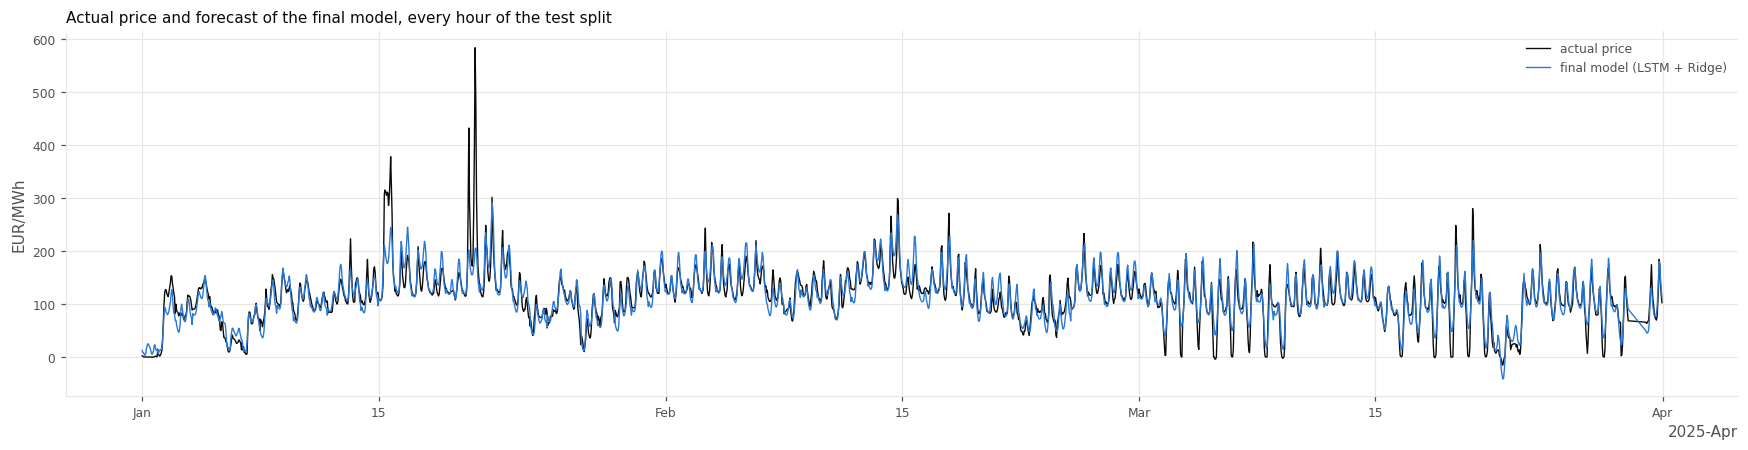

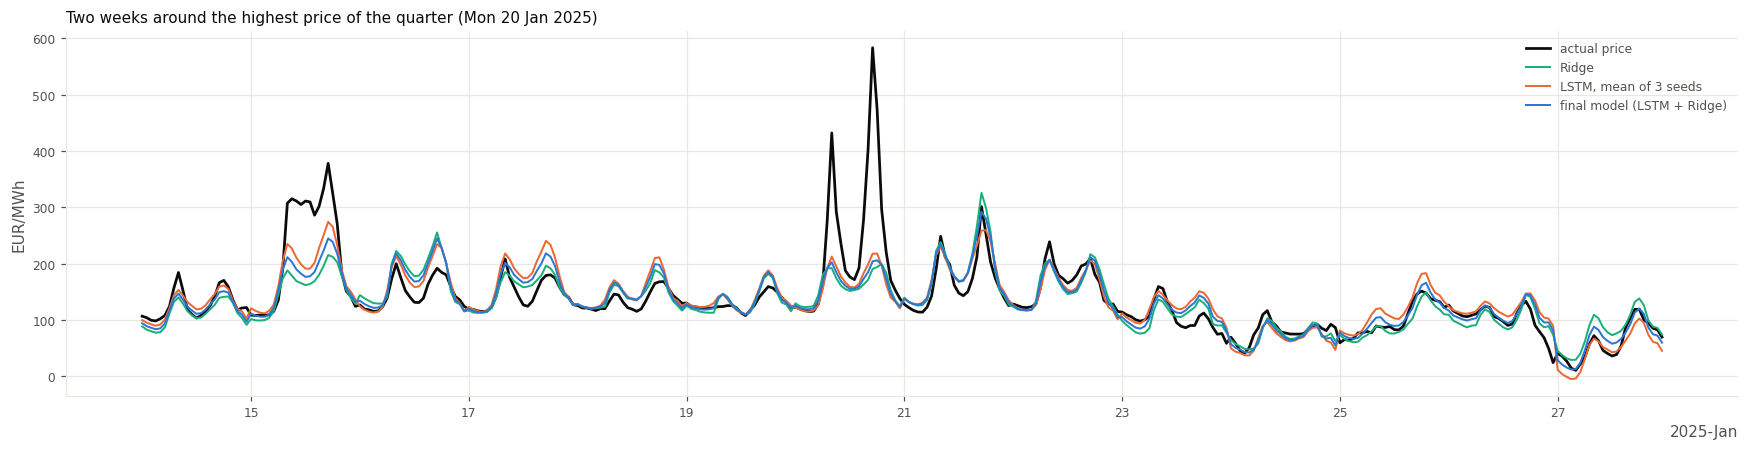

In [3]:
fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(hours, actual.ravel(), color=TEXT_COLOR, linewidth=0.9, label="actual price")
ax.plot(hours, forecasts["final model"].ravel(), color=COLORS["final model"], linewidth=0.9, label=label("final model"))
style_axes(ax, "Actual price and forecast of the final model, every hour of the test split")
ax.set_ylabel("EUR/MWh")
date_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper right")
plt.tight_layout()
plt.show()

peak_day = days[np.argmax(actual.max(axis=1))].tz_localize(None)
zoom = (hours >= peak_day - pd.Timedelta(days=6)) & (hours < peak_day + pd.Timedelta(days=8))
fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(hours[zoom], actual.ravel()[zoom], color=TEXT_COLOR, linewidth=1.8, label="actual price")
for name in MAIN:
    ax.plot(hours[zoom], forecasts[name].ravel()[zoom], color=color(name), linewidth=1.3, label=label(name))
style_axes(ax, f"Two weeks around the highest price of the quarter ({peak_day:%a %d %b %Y})")
ax.set_ylabel("EUR/MWh")
date_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper right")
plt.tight_layout()
plt.show()

## 3. Day by day

Top: the daily mean price and the range from the lowest to the highest hour of the day. Bottom: the daily MAE of the final model and of the baseline day D-1. Large errors come with wide price ranges, i.e. with spikes within the day.

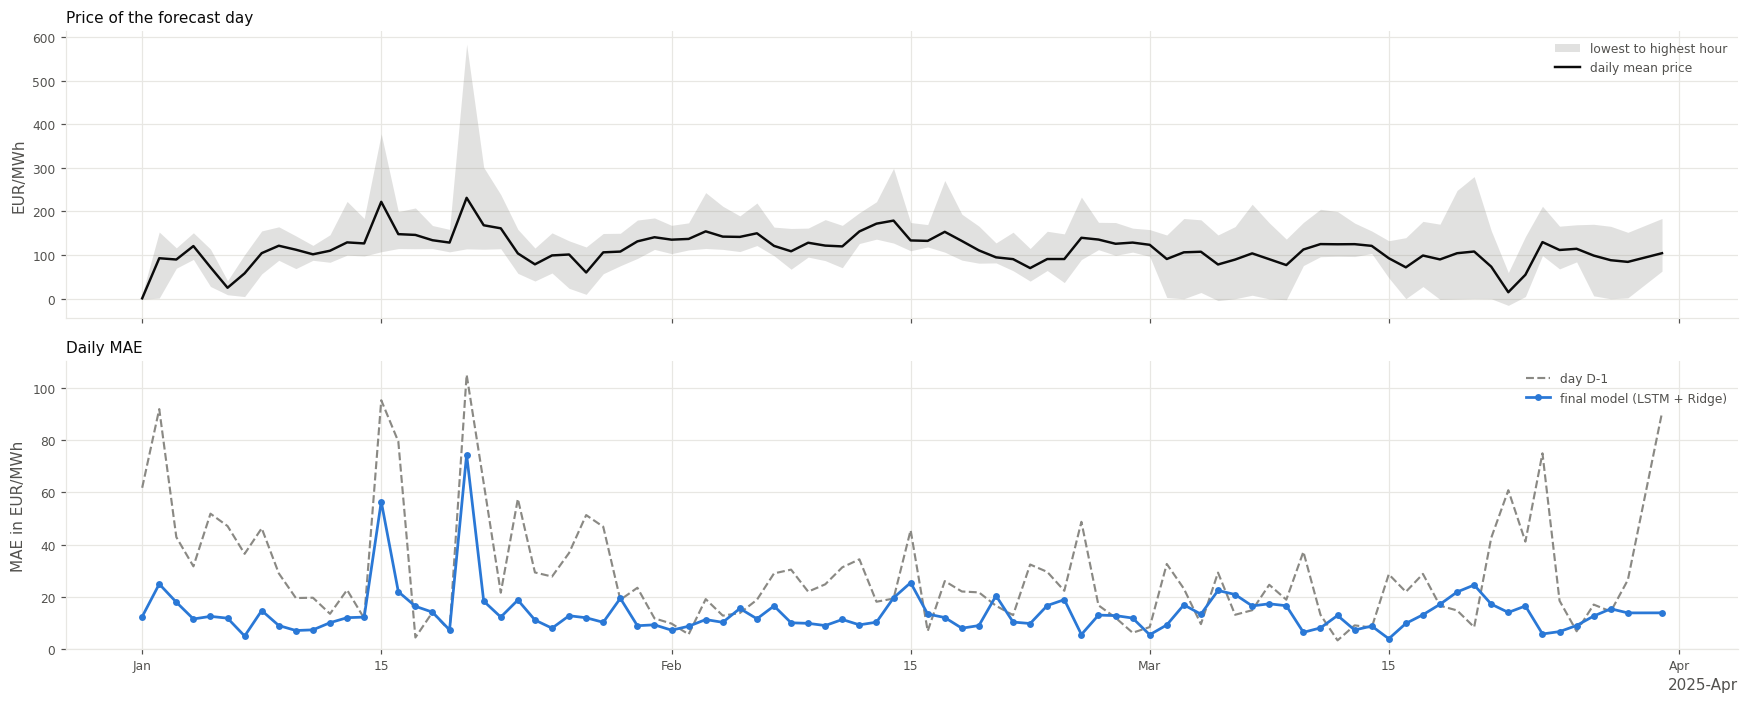

daily MAE of the final model: median 12.1, best day 3.8, worst day 74.5; better than day D-1 on 75% of the days


In [4]:
x = days.tz_localize(None)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
top.fill_between(x, actual.min(axis=1), actual.max(axis=1), color=CONTEXT_COLOR, alpha=0.25, linewidth=0,
                 label="lowest to highest hour")
top.plot(x, actual.mean(axis=1), color=TEXT_COLOR, linewidth=1.6, label="daily mean price")
style_axes(top, "Price of the forecast day")
top.set_ylabel("EUR/MWh")
top.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper right")

bottom.plot(x, daily_mae["day D-1"], color=CONTEXT_COLOR, linewidth=1.4, linestyle="--", label=label("day D-1"))
bottom.plot(x, daily_mae["final model"], color=COLORS["final model"], linewidth=1.8, marker="o", markersize=3.5,
            label=label("final model"))
style_axes(bottom, "Daily MAE")
bottom.set_ylabel("MAE in EUR/MWh")
bottom.set_ylim(bottom=0)
bottom.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper right")
date_axis(bottom)
plt.tight_layout()
plt.show()

print(f"daily MAE of the final model: median {np.median(daily_mae['final model']):.1f}, "
      f"best day {daily_mae['final model'].min():.1f}, worst day {daily_mae['final model'].max():.1f}; "
      f"better than day D-1 on {(daily_mae['final model'] < daily_mae['day D-1']).mean():.0%} of the days")

## 4. Hour of the day

The MAE of every hour of the forecast day. Where the two parts of the final model differ, the final model lies close to the better one.

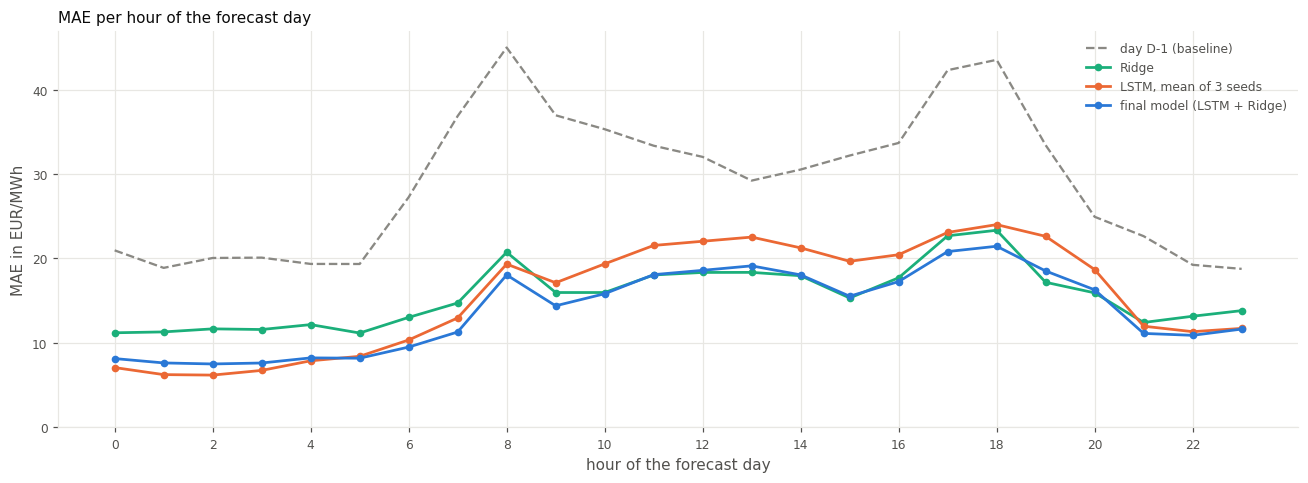

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
hour_of_day = np.arange(ds.horizon)
ax.plot(hour_of_day, np.abs(errors["day D-1"]).mean(axis=0), color=CONTEXT_COLOR, linewidth=1.5, linestyle="--",
        label="day D-1 (baseline)")
for name in MAIN:
    ax.plot(hour_of_day, np.abs(errors[name]).mean(axis=0), color=color(name), linewidth=1.8, marker="o",
            markersize=4, label=label(name))
style_axes(ax, "MAE per hour of the forecast day")
ax.set_xlabel("hour of the forecast day")
ax.set_ylabel("MAE in EUR/MWh")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR)
plt.tight_layout()
plt.show()

## 5. Weekday and price level

Left: the MAE per weekday. Right: the MAE per level of the actual price, with the number of hours in each level. The model is reliable at normal prices and loses accuracy at the extremes, where few training examples exist.

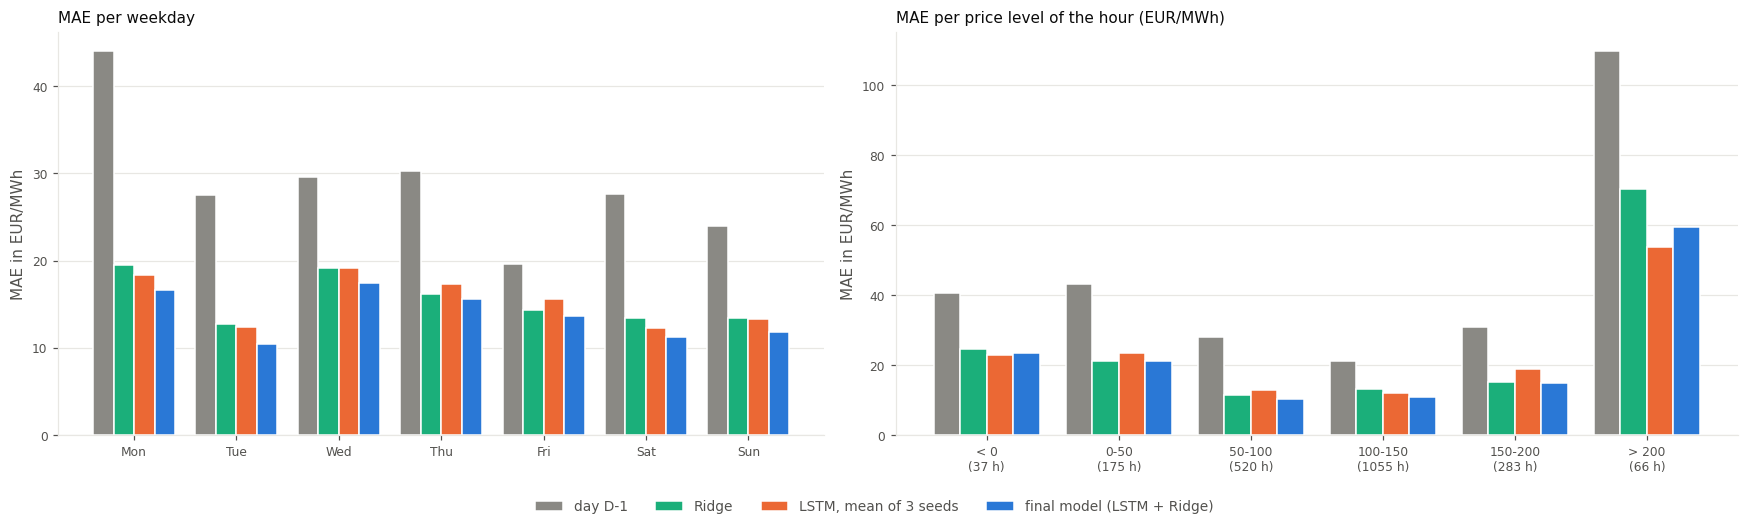

,day D-1,Ridge,"LSTM, mean of 3 seeds",final model (LSTM + Ridge)
Mon,44.0,19.5,18.3,16.7
Tue,27.5,12.7,12.3,10.4
Wed,29.5,19.1,19.1,17.5
Thu,30.3,16.1,17.3,15.6
Fri,19.6,14.3,15.6,13.6
Sat,27.6,13.4,12.2,11.3
Sun,23.9,13.4,13.3,11.9


,day D-1,Ridge,"LSTM, mean of 3 seeds",final model (LSTM + Ridge)
< 0 (37 h),40.6,24.6,23.0,23.5
0-50 (175 h),43.2,21.0,23.3,21.1
50-100 (520 h),28.0,11.5,12.9,10.4
100-150 (1055 h),21.2,13.1,12.0,11.0
150-200 (283 h),30.7,15.0,18.8,14.8
> 200 (66 h),109.8,70.2,53.6,59.4


In [6]:
def grouped_bars(ax, table, title, ylabel):
    width = 0.8 / len(table.columns)
    for k, name in enumerate(table.columns):
        ax.bar(np.arange(len(table)) + (k - (len(table.columns) - 1) / 2) * width, table[name], width=width,
               color=color(name), edgecolor="white", linewidth=1, label=label(name))
    ax.set_xticks(np.arange(len(table)), table.index)
    style_axes(ax, title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)


names = ["day D-1"] + MAIN
weekday = pd.Series(days.dayofweek, name="weekday")
by_weekday = pd.DataFrame({name: pd.Series(daily_mae[name]).groupby(weekday).mean() for name in names})
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

levels = pd.cut(actual.ravel(), [-np.inf, 0, 50, 100, 150, 200, np.inf],
                labels=["< 0", "0-50", "50-100", "100-150", "150-200", "> 200"])
by_level = pd.DataFrame({name: pd.Series(np.abs(errors[name]).ravel()).groupby(levels, observed=True).mean()
                         for name in names})
counts = pd.Series(levels).value_counts().reindex(by_level.index)
by_level.index = [f"{level}\n({n} h)" for level, n in counts.items()]

fig, (left, right) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
grouped_bars(left, by_weekday, "MAE per weekday", "MAE in EUR/MWh")
grouped_bars(right, by_level, "MAE per price level of the hour (EUR/MWh)", "MAE in EUR/MWh")
handles, labels = left.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, fontsize=9, labelcolor=MUTED_COLOR)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

for table in [by_weekday, by_level]:
    display(table.rename(columns=label, index=lambda i: " ".join(i.split())).round(1))

## 6. How the errors are distributed

Left: the signed errors of every hour (errors beyond ±150 EUR/MWh are counted at the edge). Right: forecast against actual price of every hour for the final model; points below the diagonal are forecasts that were too low. The model is unbiased at normal prices and underestimates the spikes.

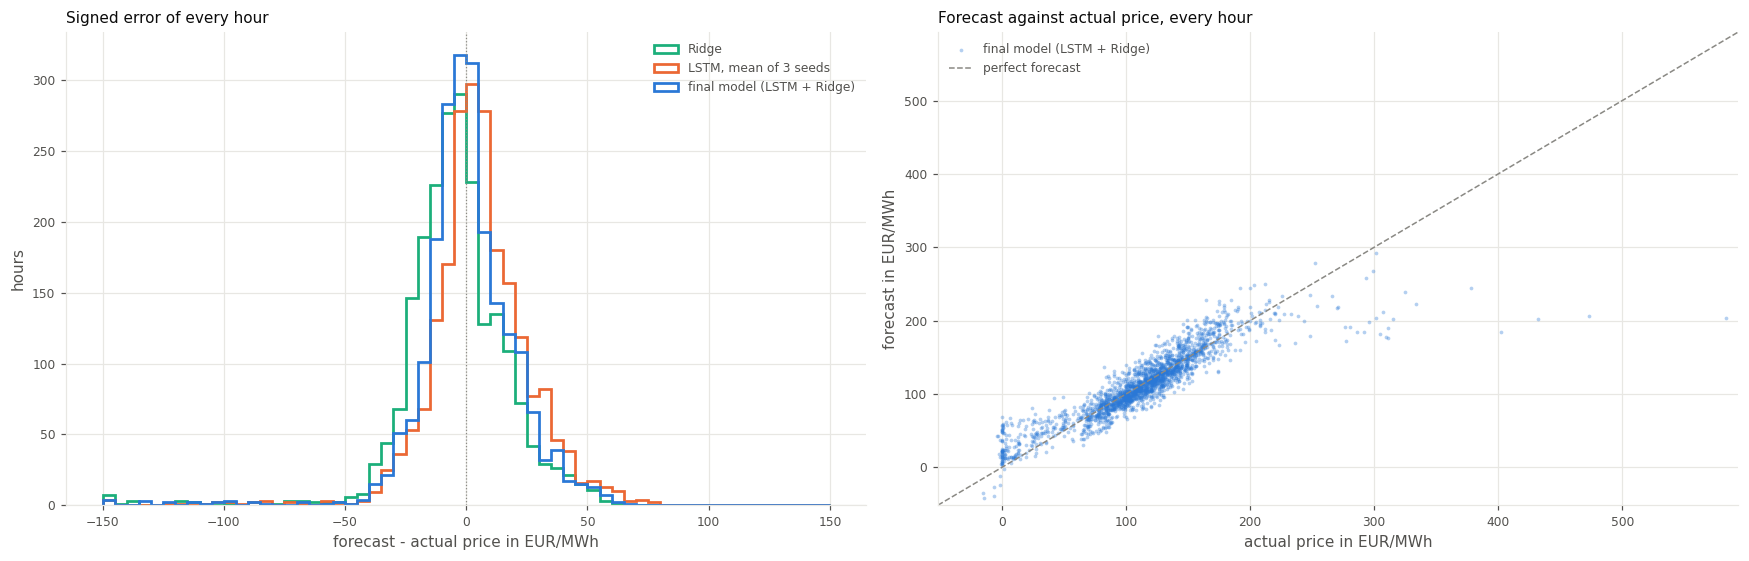

bias of the final model: +0.6 overall, +2.3 at prices up to 200, -52.8 above 200 EUR/MWh (66 hours)


In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(16, 5.2))
bins = np.arange(-150, 155, 5)
for name in MAIN:
    left.hist(np.clip(errors[name].ravel(), -150, 150), bins=bins, histtype="step", linewidth=1.8, color=color(name),
              label=label(name))
left.axvline(0, color=CONTEXT_COLOR, linewidth=0.8, linestyle=":")
style_axes(left, "Signed error of every hour")
left.set_xlabel("forecast - actual price in EUR/MWh")
left.set_ylabel("hours")
left.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR)

right.scatter(actual.ravel(), forecasts["final model"].ravel(), s=6, alpha=0.35, color=COLORS["final model"],
              linewidths=0, label=label("final model"))
limits = [min(actual.min(), forecasts["final model"].min()) - 10, actual.max() + 10]
right.plot(limits, limits, color=CONTEXT_COLOR, linewidth=1, linestyle="--", label="perfect forecast")
right.set_xlim(limits)
right.set_ylim(limits)
style_axes(right, "Forecast against actual price, every hour")
right.set_xlabel("actual price in EUR/MWh")
right.set_ylabel("forecast in EUR/MWh")
right.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

high = actual > 200
print(f"bias of the final model: {errors['final model'].mean():+.1f} overall, "
      f"{errors['final model'][~high].mean():+.1f} at prices up to 200, {errors['final model'][high].mean():+.1f} above "
      f"200 EUR/MWh ({high.sum()} hours)")

## 7. Why the ensemble works

Each point is a test day: the daily MAE of the LSTM (mean of 3 seeds) against that of Ridge. Points away from the diagonal are days on which one model is clearly better; averaging both pulls these days towards the better one. The correlation of the hourly errors measures how differently the two models err: the lower, the more the mean helps. The mean can never be worse than both parts, because the absolute error of a mean is at most the mean of the absolute errors.

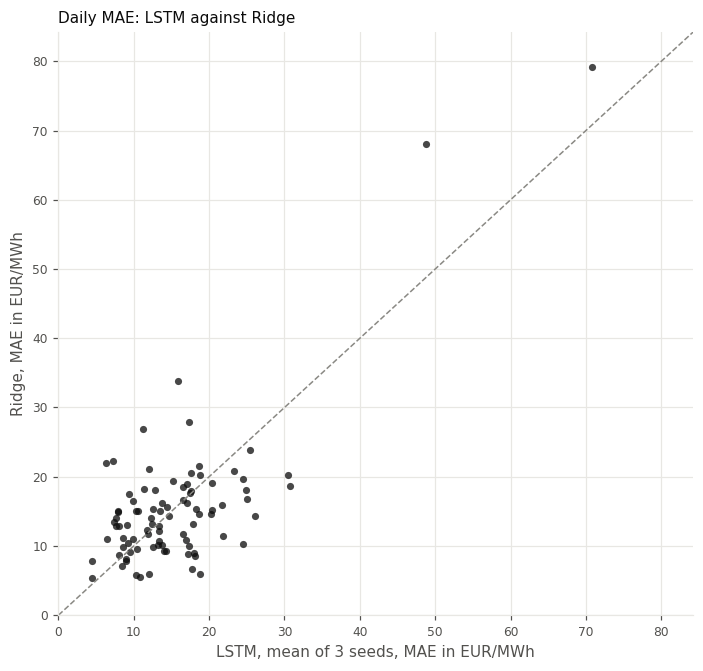

the LSTM is better on 45 days, Ridge on 44; correlation of the hourly errors 0.83
the final model is better than both of its parts on 37% of the days


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6.2))
ax.scatter(daily_mae["lstm mean"], daily_mae["ridge"], s=22, alpha=0.75, color=TEXT_COLOR, linewidths=0)
upper = max(daily_mae["lstm mean"].max(), daily_mae["ridge"].max()) + 5
ax.plot([0, upper], [0, upper], color=CONTEXT_COLOR, linewidth=1, linestyle="--")
ax.set_xlim(0, upper)
ax.set_ylim(0, upper)
style_axes(ax, "Daily MAE: LSTM against Ridge")
ax.set_xlabel(f"{label('lstm mean')}, MAE in EUR/MWh")
ax.set_ylabel(f"{label('ridge')}, MAE in EUR/MWh")
plt.tight_layout()
plt.show()

lstm_better = daily_mae["lstm mean"] < daily_mae["ridge"]
print(f"the LSTM is better on {lstm_better.sum()} days, Ridge on {(~lstm_better).sum()}; correlation of the hourly "
      f"errors {np.corrcoef(errors['lstm mean'].ravel(), errors['ridge'].ravel())[0, 1]:.2f}")
# the final model can never be worse than both parts: the absolute error of a mean is at most the mean of the errors
both = (daily_mae["final model"] < daily_mae["lstm mean"]) & (daily_mae["final model"] < daily_mae["ridge"])
print(f"the final model is better than both of its parts on {both.mean():.0%} of the days")

## 8. Single days

Six test days: a typical day (median error), the best and the worst forecast, the highest and the lowest price, and a typical Sunday. Gray: the known prices of the two days before the forecast.

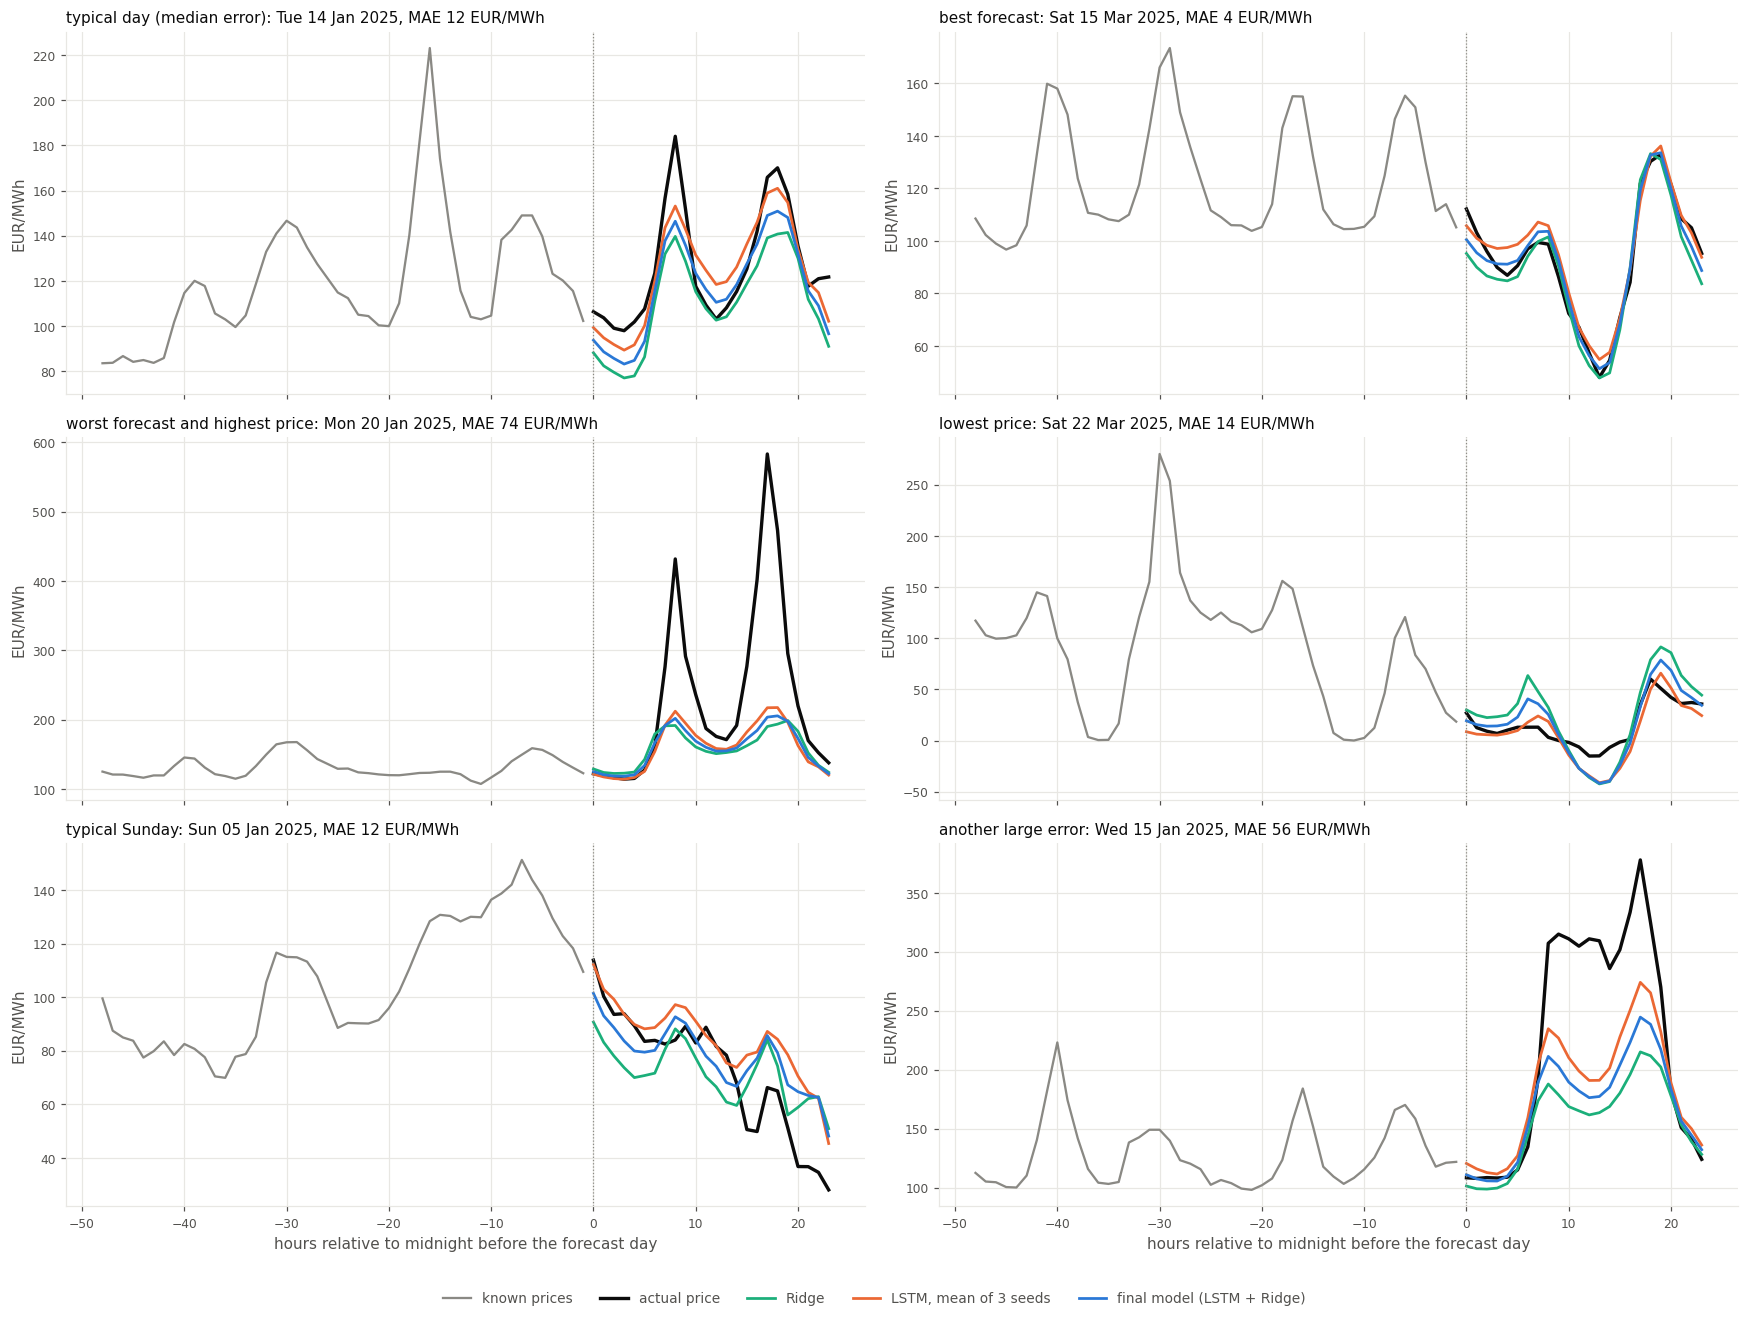

In [9]:
final_mae = daily_mae["final model"]
sundays = np.flatnonzero(days.dayofweek == 6)
choices = [("typical day (median error)", np.argsort(final_mae)[len(final_mae) // 2]),
           ("best forecast", np.argmin(final_mae)),
           ("worst forecast", np.argmax(final_mae)),
           ("highest price", np.argmax(actual.max(axis=1))),
           ("lowest price", np.argmin(actual.min(axis=1))),
           ("typical Sunday", sundays[np.argsort(final_mae[sundays])[len(sundays) // 2]])]
picks = {}
for title, i in choices:
    picks.setdefault(int(i), []).append(title)
# a day that fills several roles gets one panel, the next largest errors fill the free panels
for i in np.argsort(final_mae)[::-1]:
    if len(picks) == len(choices):
        break
    picks.setdefault(int(i), ["another large error"])

fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True)
for ax, (i, titles) in zip(axes.flat, picks.items()):
    plot_day(ax, ds, i, {name: scaled[name][i] for name in MAIN},
             f"{' and '.join(titles)}: {days[i]:%a %d %b %Y}, MAE {final_mae[i]:.0f} EUR/MWh")
for ax in axes[-1]:
    ax.set_xlabel("hours relative to midnight before the forecast day")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, fontsize=9, labelcolor=MUTED_COLOR)
fig.tight_layout(rect=(0, 0.035, 1, 1))
plt.show()

## Summary

- **Overall:** MAE 13.9 EUR/MWh, median error 9.5; 52 % of the hours are within 10 and 78 % within 20 EUR/MWh. The final model beats the prices of the day before on 75 % of the days.
- **Where it works:** typical days (median daily MAE 12.1, best day 3.8), prices between 50 and 150 EUR/MWh (MAE 10 to 11) and the night hours.
- **Where it fails:** price spikes. On 15 and 20 January the daily MAE is 56 and 74 EUR/MWh, and the 66 hours above 200 EUR/MWh are forecast 53 EUR/MWh too low on average. Above 200 the LSTM alone is the best part (53.6 against 70.2 for Ridge). Negative and very low prices are harder as well (MAE 21 to 24).
- **Weekdays:** Monday and Wednesday are the hardest days (about 17), Tuesday the easiest (10). On Mondays the prices of the day before are a poor guide (44), the calendar features fix most of that.
- **Why the ensemble works:** the two parts have opposite biases, the LSTM forecasts 5.4 EUR/MWh too high on average and Ridge 4.2 too low, their mean only 0.6. And they err on different days: each part is better on about half of the days (45 and 44), their hourly errors correlate with 0.83, and the mean beats both parts on 37 % of the days.
- **Seeds:** single LSTMs reach 14.9 to 17.2 EUR/MWh; only their mean, together with Ridge, is reliable.